# 01 — Credit Risk: Data Acquisition & Exploratory Data Analysis

## Objective
Understand the UCI Default of Credit Card Clients dataset, validate its structure and quality, and identify initial borrower-risk patterns.

**Target:** `DEFAULT` (1 = default next month; 0 = no default).  
**Important limitation:** this is a historical Taiwan credit-card dataset, not an Indian NBFC portfolio.

In [9]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Load the dataset and inspect its structure

In [8]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [4]:
!pwd

'pwd' is not recognized as an internal or external command,
operable program or batch file.


In [5]:
!pip install xlrd


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [10]:
from src.data_preprocessing import load_credit_data, basic_quality_report
df = load_credit_data(PROJECT_ROOT / "data" / "raw")
print(basic_quality_report(df))
display(df.head())

{'shape': (30000, 25), 'duplicate_rows': 0, 'missing_cells': 0, 'target_counts': {0: 23364, 1: 6636}, 'target_rate': 0.2212}


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Data types and descriptive statistics

In [11]:
display(df.info())
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ID         30000 non-null  int64
 1   LIMIT_BAL  30000 non-null  int64
 2   SEX        30000 non-null  int64
 3   EDUCATION  30000 non-null  int64
 4   MARRIAGE   30000 non-null  int64
 5   AGE        30000 non-null  int64
 6   PAY_0      30000 non-null  int64
 7   PAY_2      30000 non-null  int64
 8   PAY_3      30000 non-null  int64
 9   PAY_4      30000 non-null  int64
 10  PAY_5      30000 non-null  int64
 11  PAY_6      30000 non-null  int64
 12  BILL_AMT1  30000 non-null  int64
 13  BILL_AMT2  30000 non-null  int64
 14  BILL_AMT3  30000 non-null  int64
 15  BILL_AMT4  30000 non-null  int64
 16  BILL_AMT5  30000 non-null  int64
 17  BILL_AMT6  30000 non-null  int64
 18  PAY_AMT1   30000 non-null  int64
 19  PAY_AMT2   30000 non-null  int64
 20  PAY_AMT3   30000 non-null  int64
 21  PAY_AMT4   3

None

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


## 3. Missing values, duplicates, and target distribution

In [12]:
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
    "unique_values": df.nunique()
}).sort_values("missing_pct", ascending=False)
display(quality)
print("Duplicate rows:", df.duplicated().sum())
display(df["DEFAULT"].value_counts().rename("customer_count").to_frame())
print(f"Default rate: {df['DEFAULT'].mean():.2%}")

,missing_count,missing_pct,unique_values
ID,0,0.0,30000
BILL_AMT2,0,0.0,22346
PAY_AMT6,0,0.0,6939
PAY_AMT5,0,0.0,6897
PAY_AMT4,0,0.0,6937
PAY_AMT3,0,0.0,7518
PAY_AMT2,0,0.0,7899
PAY_AMT1,0,0.0,7943
BILL_AMT6,0,0.0,20604
BILL_AMT5,0,0.0,21010


Duplicate rows: 0


,customer_count
DEFAULT,
0,23364
1,6636


Default rate: 22.12%


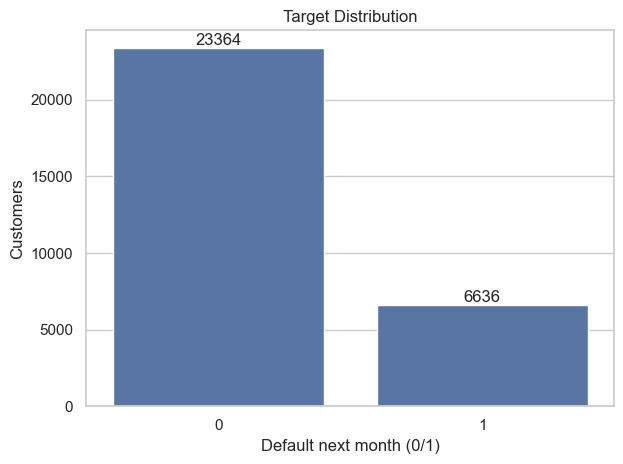

In [13]:
ax = sns.countplot(data=df, x="DEFAULT")
ax.set(title="Target Distribution", xlabel="Default next month (0/1)", ylabel="Customers")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "eda_target_distribution.png", dpi=200)
plt.show()

## 4. Univariate and bivariate analysis

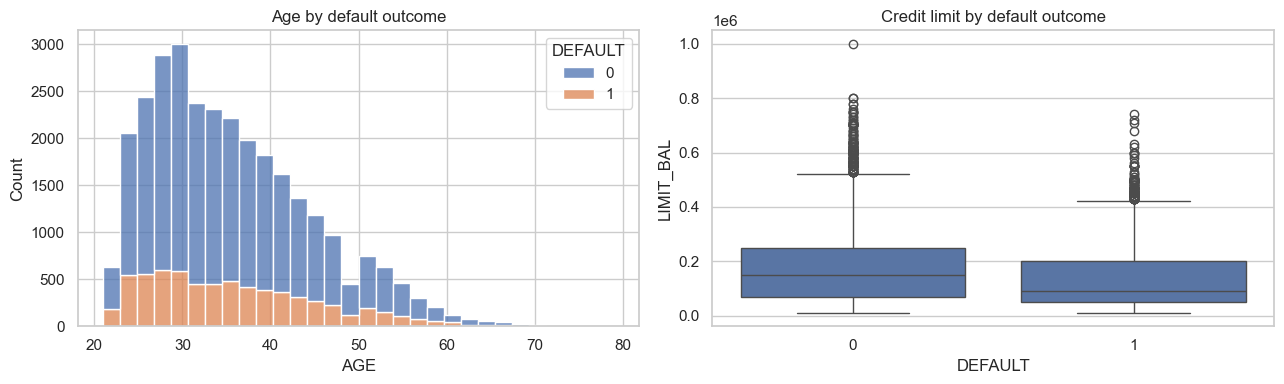

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="AGE", hue="DEFAULT", bins=30, multiple="stack", ax=axes[0])
sns.boxplot(data=df, x="DEFAULT", y="LIMIT_BAL", ax=axes[1])
axes[0].set_title("Age by default outcome")
axes[1].set_title("Credit limit by default outcome")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "eda_age_credit_limit.png", dpi=200)
plt.show()

## 5. Repayment behaviour analysis

In [15]:
repayment_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
display(df.groupby("DEFAULT")[repayment_cols].mean().T)

DEFAULT,0,1
PAY_0,-0.211222,0.668174
PAY_2,-0.301917,0.458258
PAY_3,-0.316256,0.362116
PAY_4,-0.355633,0.254521
PAY_5,-0.389488,0.167872
PAY_6,-0.405624,0.112116


## 6. Correlation analysis

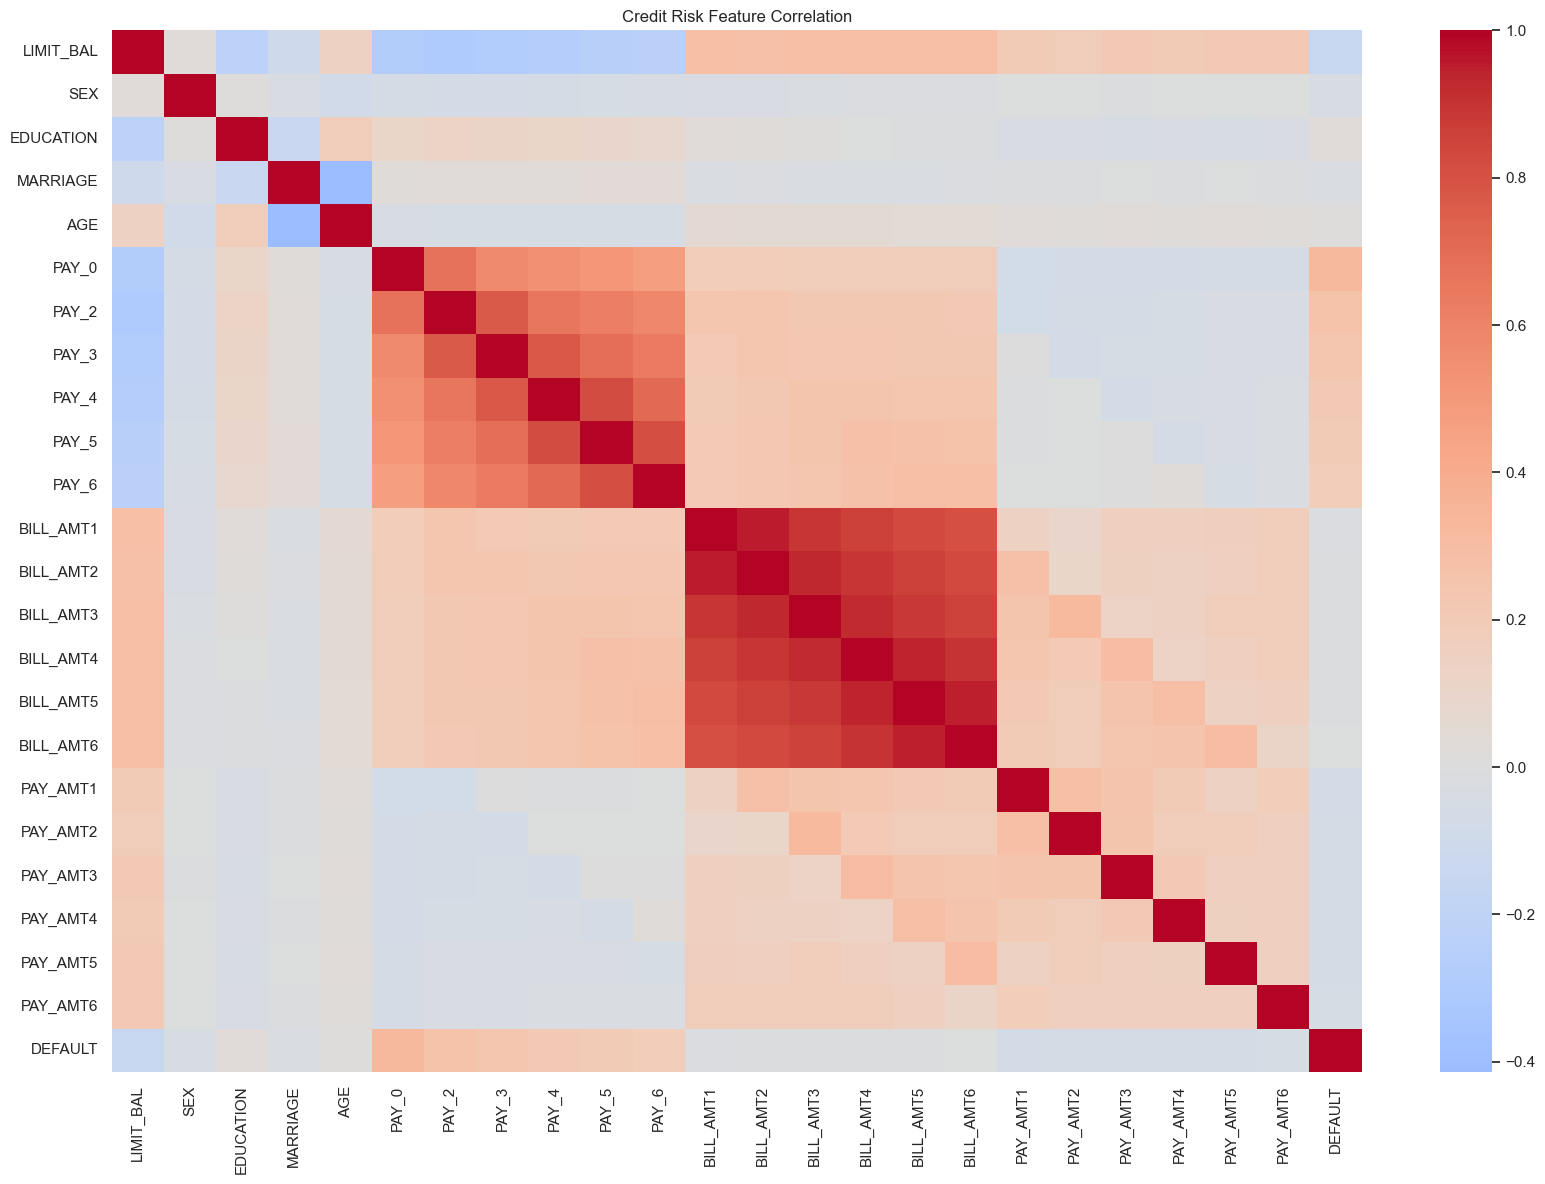

,correlation_with_default
PAY_0,0.324794
PAY_2,0.263551
PAY_3,0.235253
PAY_4,0.216614
PAY_5,0.204149
PAY_6,0.186866
EDUCATION,0.028006
AGE,0.013890
BILL_AMT6,-0.005372
BILL_AMT5,-0.006760


In [16]:
corr = df.drop(columns=["ID"], errors="ignore").corr(numeric_only=True)
plt.figure(figsize=(17, 12))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Credit Risk Feature Correlation")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "eda_correlation.png", dpi=200)
plt.show()
display(corr["DEFAULT"].drop("DEFAULT").sort_values(ascending=False).to_frame("correlation_with_default"))

## 7. Save raw CSV and EDA summaries

In [17]:
raw_csv = PROJECT_ROOT / "data" / "raw" / "credit_risk_data.csv"
df.to_csv(raw_csv, index=False)
quality.to_csv(PROJECT_ROOT / "reports" / "eda_data_quality.csv")
df.describe().T.to_csv(PROJECT_ROOT / "reports" / "eda_descriptive_statistics.csv")
print("Saved:", raw_csv)

Saved: \\wsl.localhost\Ubuntu\home\tejaswinich17\Credit-Risk-ML\Credit-Risk-ML\data\raw\credit_risk_data.csv


## 8. Initial interpretation

Discuss the observed default rate, repayment status patterns, and whether credit limit appears associated with default. Do not infer causation from these descriptive plots. The dataset is cross-sectional/historical and does not provide a genuine monthly observation timeline for out-of-time validation.